In [1]:
import os
os.chdir(r"C:\Users\Alive\Documents\eeg-brain-networks-dementia")
print(os.getcwd())

C:\Users\Alive\Documents\eeg-brain-networks-dementia


<EpochsFIF | 60 events (all good), 0 – 3.998 s (baseline off), ~17.4 MiB, data loaded,
 '1': 60>
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


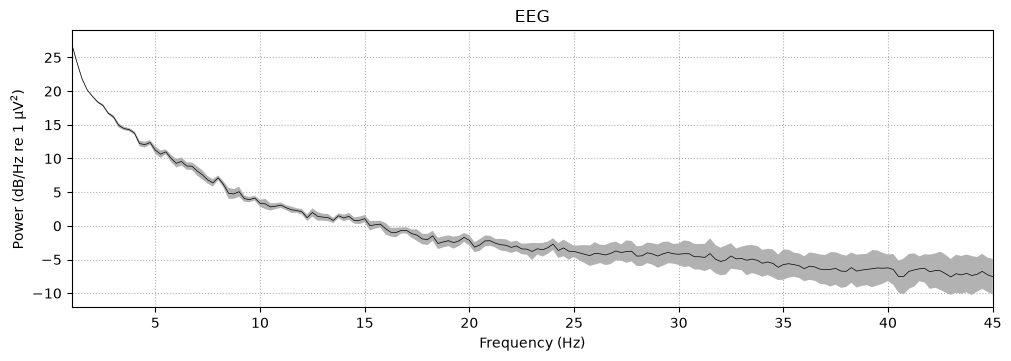

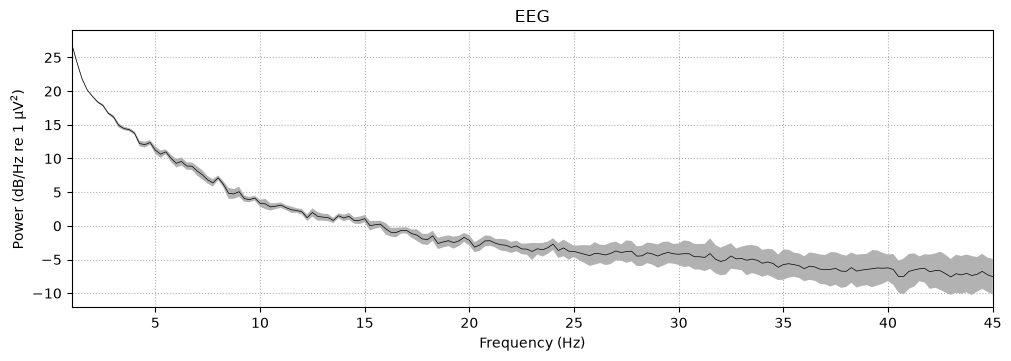

In [2]:
import mne
ep = mne.read_epochs("data/epochs/sub-001-epo.fif", preload=True, verbose=False)
print(ep)
ep.compute_psd(method="welch", fmin=1, fmax=45).plot(average=True)

In [3]:
import numpy as np, pandas as pd, mne

BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}

def band_power_per_channel(epochs):
    """Relative band power per channel, shape (n_bands, n_channels)."""
    spec = epochs.compute_psd(method="welch", fmin=1, fmax=45, verbose=False)
    psd, freqs = spec.get_data(return_freqs=True)    # epochs x channels x freqs
    psd = psd.mean(axis=0)                            # average over epochs
    total = psd.sum(axis=1)                           # total power per channel, 1-45 Hz
    rel = []
    for name, (lo, hi) in BANDS.items():
        upper = (freqs <= hi) if name == "gamma" else (freqs < hi)
        mask = (freqs >= lo) & upper
        rel.append(psd[:, mask].sum(axis=1) / total)
    return np.array(rel)

In [4]:
ep = mne.read_epochs("data/epochs/sub-001-epo.fif", preload=True, verbose=False)
rel = band_power_per_channel(ep)
print(rel.shape)
print("Sum over bands (should be 1.0 for every channel):", rel.sum(axis=0).round(3))
for (name, _), row in zip(BANDS.items(), rel):
    print(f"{name:6s} mean relative power = {row.mean():.3f}")

(5, 19)
Sum over bands (should be 1.0 for every channel): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
delta  mean relative power = 0.833
theta  mean relative power = 0.103
alpha  mean relative power = 0.028
beta   mean relative power = 0.026
gamma  mean relative power = 0.010


In [5]:

import os
def spectral_row(sub_id, epochs):
    rel = band_power_per_channel(epochs)              # (5, 19)
    row = {"participant_id": sub_id}
    for (name, _), vals in zip(BANDS.items(), rel):
        row[f"relpow_{name}"] = vals.mean()
    row["theta_alpha_ratio"] = row["relpow_theta"] / row["relpow_alpha"]
    chan_row = {"participant_id": sub_id}
    for (name, _), vals in zip(BANDS.items(), rel):
        for ch, v in zip(epochs.ch_names, vals):
            chan_row[f"{name}_{ch}"] = v
    return row, chan_row

df = pd.read_csv("data/ds004504/participants.tsv", sep="\t")
rows, chan_rows = [], []
for sub in ["sub-001", "sub-037", "sub-066"]:
    ep = mne.read_epochs(f"data/epochs/{sub}-epo.fif", preload=True, verbose=False)
    r, c = spectral_row(sub, ep)
    rows.append(r); chan_rows.append(c)

groups = df[["participant_id", "Group"]]
spec = pd.DataFrame(rows).merge(groups, on="participant_id")
spec_ch = pd.DataFrame(chan_rows).merge(groups, on="participant_id")
print(spec.round(3))

os.makedirs("results/tables", exist_ok=True)
spec.to_csv("results/tables/spectral_features.csv", index=False)
spec_ch.to_csv("results/tables/spectral_features_channels.csv", index=False)

  participant_id  relpow_delta  relpow_theta  relpow_alpha  relpow_beta  \
0        sub-001         0.833         0.103         0.028        0.026   
1        sub-037         0.763         0.097         0.103        0.030   
2        sub-066         0.786         0.120         0.054        0.029   

   relpow_gamma  theta_alpha_ratio Group  
0         0.010              3.696     A  
1         0.007              0.940     C  
2         0.010              2.209     F  


In [1]:
import os
from pathlib import Path
root = Path.cwd()
while not (root / ".git").exists():
    root = root.parent
os.chdir(root)
print(os.getcwd())

c:\Users\Alive\Documents\eeg-brain-networks-dementia


In [2]:
%%writefile src/spectral.py
import numpy as np

BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}


def band_power_per_channel(epochs):
    """Relative band power per channel, shape (n_bands, n_channels)."""
    spec = epochs.compute_psd(method="welch", fmin=1, fmax=45, verbose=False)
    psd, freqs = spec.get_data(return_freqs=True)    # epochs x channels x freqs
    psd = psd.mean(axis=0)                            # average over epochs
    total = psd.sum(axis=1)                           # total power per channel, 1-45 Hz
    rel = []
    for name, (lo, hi) in BANDS.items():
        upper = (freqs <= hi) if name == "gamma" else (freqs < hi)
        mask = (freqs >= lo) & upper
        rel.append(psd[:, mask].sum(axis=1) / total)
    return np.array(rel)


def spectral_row(sub_id, epochs):
    """One summary row and one per-channel row for a subject."""
    rel = band_power_per_channel(epochs)
    row = {"participant_id": sub_id}
    chan_row = {"participant_id": sub_id}
    for (name, _), vals in zip(BANDS.items(), rel):
        row[f"relpow_{name}"] = vals.mean()
        for ch, v in zip(epochs.ch_names, vals):
            chan_row[f"{name}_{ch}"] = v
    row["theta_alpha_ratio"] = row["relpow_theta"] / row["relpow_alpha"]
    return row, chan_row

Writing src/spectral.py


In [3]:
print(os.listdir("src"))

['.gitkeep', 'connectivity.py', 'epoching.py', 'spectral.py', '__pycache__']


In [4]:
import sys
import pandas as pd, mne
sys.path.append("src")
import spectral
mne.set_log_level("ERROR")

df = pd.read_csv("data/ds004504/participants.tsv", sep="\t")
rows, chan_rows = [], []
for sub in df["participant_id"]:
    f = f"data/epochs/{sub}-epo.fif"
    if not os.path.exists(f):
        print("skipping", sub, "(no epoch file)")
        continue
    ep = mne.read_epochs(f, preload=True, verbose=False)
    r, c = spectral.spectral_row(sub, ep)
    rows.append(r); chan_rows.append(c)

groups = df[["participant_id", "Group"]]
spec = pd.DataFrame(rows).merge(groups, on="participant_id")
spec_ch = pd.DataFrame(chan_rows).merge(groups, on="participant_id")
spec.to_csv("results/tables/spectral_features.csv", index=False)
spec_ch.to_csv("results/tables/spectral_features_channels.csv", index=False)

print(spec.groupby("Group").size())
print(spec.groupby("Group")[["relpow_delta", "relpow_theta", "relpow_alpha", "theta_alpha_ratio"]].median().round(3))

skipping sub-086 (no epoch file)
Group
A    36
C    29
F    22
dtype: int64
       relpow_delta  relpow_theta  relpow_alpha  theta_alpha_ratio
Group                                                             
A             0.805         0.103         0.039              2.818
C             0.803         0.092         0.065              1.406
F             0.808         0.096         0.041              2.200
